# AIFS and IFS, side by side over Senegal 🤖
### ECMWF free & open data · machine-learned and physics-based · no account

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/aifs_vs_ifs.ipynb)

ECMWF runs two global forecasts and both are **open data**: the physics-based **IFS** and **AIFS**, the
machine-learned model, which produces a ten-day forecast in minutes. This notebook takes the same run of each, maps
2 m temperature three days ahead side by side, then maps the difference between them.

*In Google Colab? Press **Runtime → Run all**. Nothing to install, no account needed.*

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes ~1 minute.
!pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the area and the lead time

In [3]:
AREA = [22.0, -22.0, 8.0, -6.0]             # north, west, south, east
STEP = 60                                   # hours after the run starts (about two and a half days)
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get both forecasts (ECMWF open data, 0.25°)

In [4]:
def get(model):
    fl = ekd.from_source("ecmwf-open-data", model=model, param="2t", step=STEP).to_fieldlist()
    x = fl.to_xarray()
    x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude")
    x = x.sel(latitude=slice(AREA[0], AREA[2]), longitude=slice(AREA[1], AREA[3]))
    return fl, x[list(x.data_vars)[0]].squeeze() - 273.15

ifs_fl, ifs = get("ifs")
aifs_fl, aifs = get("aifs-single")
run, valid = ifs_fl[0].time.base_datetime(), ifs_fl[0].time.valid_datetime()
assert aifs_fl[0].time.base_datetime() == run, "the two models came from different runs: run the cell again"
diff = aifs - ifs
print(f"Run {run:%d %B %Y %H} UTC, valid {valid:%A %d %B %H}:00 UTC")
print(f"IFS {float(ifs.min()):.0f} to {float(ifs.max()):.0f} °C · AIFS {float(aifs.min()):.0f} to {float(aifs.max()):.0f} °C")
print(f"AIFS minus IFS: mean {float(diff.mean()):+.1f} °C, typical size {float(np.sqrt((diff ** 2).mean())):.1f} °C")

By downloading data from the ECMWF open data dataset, you agree to the terms: Attribution 4.0 International (CC BY 4.0). Please attribute ECMWF when downloading this data.


Run 19 November 2026 06 UTC, valid Saturday 21 November 18:00 UTC
IFS 22 to 36 °C · AIFS 23 to 38 °C
AIFS minus IFS: mean +0.6 °C, typical size 1.2 °C


## 3 · Map them

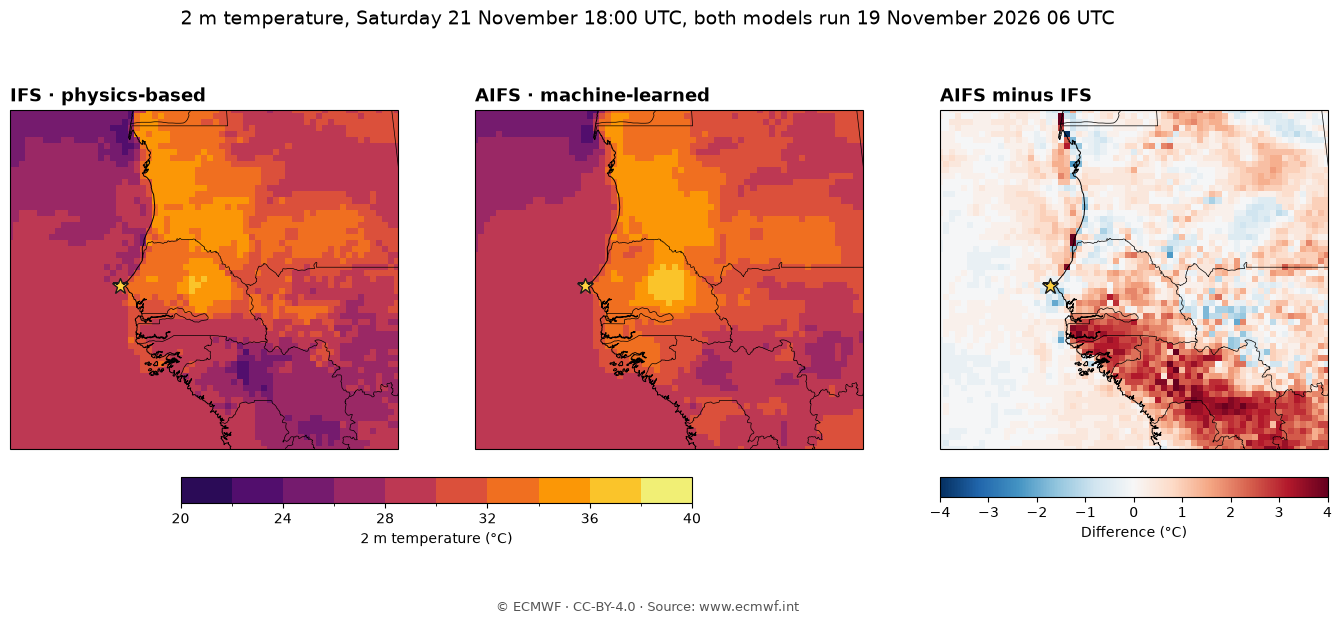

In [5]:
from matplotlib.colors import BoundaryNorm, ListedColormap
levels = [20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40]
cmap = ListedColormap(plt.get_cmap("inferno")(np.linspace(0.15, 0.95, len(levels) - 1)))
fig, axs = plt.subplots(1, 3, figsize=(17, 6.2), subplot_kw=dict(projection=ccrs.PlateCarree()))
for ax, da, title in ((axs[0], ifs, "IFS · physics-based"), (axs[1], aifs, "AIFS · machine-learned")):
    m = ax.pcolormesh(da.longitude, da.latitude, da, cmap=cmap, norm=BoundaryNorm(levels, cmap.N))
    ax.set_title(title, fontsize=13, fontweight="bold", loc="left")
fig.colorbar(m, ax=axs[:2], orientation="horizontal", shrink=0.6, pad=0.06, label="2 m temperature (°C)")
d = axs[2].pcolormesh(diff.longitude, diff.latitude, diff, cmap="RdBu_r", vmin=-4, vmax=4)
axs[2].set_title("AIFS minus IFS", fontsize=13, fontweight="bold", loc="left")
fig.colorbar(d, ax=axs[2], orientation="horizontal", pad=0.06, label="Difference (°C)")
for ax in axs:
    ax.set_extent([AREA[1], AREA[3], AREA[2], AREA[0]]); ax.coastlines(lw=0.7); ax.add_feature(__import__("cartopy").feature.BORDERS, lw=0.5)
    ax.plot(-17.467, 14.716, "*", ms=12, color="#ffd23f", mec="#1a1a1a", transform=ccrs.PlateCarree())
fig.suptitle(f"2 m temperature, {valid:%A %d %B %H}:00 UTC, both models run {run:%d %B %Y %H} UTC", fontsize=14)
fig.text(0.5, 0.01, "© ECMWF · CC-BY-4.0 · Source: www.ecmwf.int", ha="center", fontsize=9, color="#555")
fig.savefig("aifs_vs_ifs.png", dpi=110, bbox_inches="tight")
plt.show()

## 4 · Your turn 🌍

- **Further ahead:** `STEP = 144` (six days). The two models usually drift further apart with lead time.
- **Another variable:** `param="10u"` or `"msl"` (mean sea level pressure; divide by 100 for hPa).
- **The ensembles:** both have open ensembles too: `model="aifs-ens"` or `"ifs"` with `stream="enfo"`.

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. No account, no key.

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)